# Policy gradients, live: REINFORCE → PPO → GRPO (~1 hr)

**Overview** We write the three algorithms by hand, in the same
shapes and names as the RLHF Book code (`rlhf-book/code/policy_gradients/`), and train each one on a toy
version of the task the book's configs use (`spell_backward`). Everything else (task, tiny model, rollouts,
training loop) is already written, so the time goes into the algorithms.

| Min | Section | What gets written live |
| --- | --- | --- |
| 0–5 | §0–§4 tour: task, model, `Experience`, training loop | nothing (run before the session) |
| 5–17 | §5 REINFORCE, then add a baseline | `ReinforceLoss`, `compute_batch_mean_advantages` (1 line) |
| 17–32 | §6 PPO | `compute_gae`, `PPOLoss` |
| 32–42 | §7 GRPO | `compute_standardized_advantages`, `GRPOLoss` (+ k3 KL) |
| 42–45 | §8 compare all three: curves, cost table, §8b gradient noise (§8b can move into the buffer) | nothing |
| 45-60+ | §9 stretch: RLOO, Dr. GRPO, KL on/off, discussion | optional |

Each algorithm section runs in the same order: **Recap** (the math, in the notation below) → **In code** (which
symbol is which tensor) → write the code → run the checks → train → **Ask the room**.

**Running it:** *Run All*. The SFT warm-up that makes the "base model" takes ~20 s on one RTX 3090 (~75 s on a
48-core CPU), and each 200-step training run takes 5–25 s on the GPU (10–25 s on that CPU). Runs are deterministic on
a given machine and device. The saved outputs are seed 0 on an RTX 3090. On CPU the numbers differ but the story is
the same (measured: REINFORCE collapses to 0.0, the others reach 0.90–0.98).

**Conventions, the same as `rlhf-book/code/policy_gradients`:**
- `sequence_ids` (B, S): left-padded prompt + completion, right-padded with `PAD` after `EOS`.
- `log_probs`, `action_mask`, `values`, per-token `advantages` are all (B, S-1). Position `t` scores token `t+1`.
  `action_mask` is True only on generated tokens (including `EOS`).
- Sequence-level `advantages` and `rewards` are (B, 1) and broadcast over tokens.
- Losses are *minimized*. Per-token loss → `masked_mean` over each sequence's tokens → mean over the batch.

**Notation.** The math follows [*RL for LLM Post-Training: Foundations of Policy Gradients*](https://github.com/aniketrege/hackmd-writeups/blob/main/rl_post_training/policy_gradient_algorithms.md)
(adapted from RLHF Book Ch. 6). The code names follow the book's code. Every algorithm section has its own math → code table.

| Symbol | Meaning | In code |
| --- | --- | --- |
| $x$, $y=(y_1,\dots,y_T)$, $\tau=(x,y)$ | prompt, completion, trajectory | one row of `sequence_ids` |
| $s_t=(x,y_{<t})$, $a_t=y_t$ | state (prefix), action (next token) | a position in the (B, S-1) tensors; `action_mask` is True on the $T$ action positions |
| $\pi_\theta(a_t\mid s_t)$ | policy being trained | `log_probs` = $\log\pi_\theta$ (B, S-1), has grad |
| $\pi_{\theta_{\text{old}}}$ | rollout policy: the frozen snapshot that sampled this batch | `experience.log_probs_old` |
| $\pi_{\text{ref}}$ | fixed reference policy (here the SFT model) | `experience.log_probs_ref` (only if $\beta>0$) |
| $R(\tau)$ | terminal reward | `experience.rewards` (B, 1) |
| $\Psi_t$, $\hat A_t$ | per-token weight in the policy gradient; advantage estimate | `experience.advantages`: (B, 1) sequence-level or (B, S-1) per token |
| $V_\phi(s_t)$, $V_{\phi_{\text{old}}}(s_t)$ | critic now, and at rollout time | `values`, `experience.values_old` |
| $\gamma$, $\lambda$ | discount, GAE mixing | `gamma=1.0`, `lam=0.98` |
| $\epsilon$, $\beta$ | clip range, KL coefficient | `clip_eps_lo = clip_eps_hi = 0.2`, `beta=0` |
| $N$; $K$ (RLOO), $G$ (GRPO) | rollouts per batch; completions per prompt | `B`; `num_rollouts` |

The writeup's objectives ($J$, $L^{CLIP}$) are *maximized*; the code minimizes their negatives.

**Map to the book's code** (read after the session):

| Here | rlhf-book |
| --- | --- |
| `ReinforceLoss`, `PPOLoss`, `GRPOLoss`, `masked_mean`, `approx_kl3` | `code/policy_gradients/loss.py` |
| `compute_gae`, `compute_standardized_advantages`, `compute_log_probs`, `get_val_model` | `code/policy_gradients/utils.py` |
| `rollout` | `code/policy_gradients/rollout.py` (`RolloutEngine._generate_experience`) |
| `train` | `code/policy_gradients/train.py` |
| hyperparameters | `code/policy_gradients/configs/{reinforce,ppo,grpo}.yaml` |

The lectures that go with this are `rlhf-book/teach/course/lec3-chap6-p1.md`, which covers the math (policy
gradient, baselines, REINFORCE, RLOO, why PPO, GRPO), and `lec4-chap6-p2.md`, which covers the losses in code (GAE,
clipped surrogate, critic loss, GRPO). The book chapter is Chapter 6, *Policy Gradient Methods*.

**Differences from the book's code, on purpose:** a 2-layer transformer instead of Qwen3-1.7B, an SFT warm-up instead of a
pretrained model, a toy `spell_backward` with the same reward shape (correctness + 0.5·format), plain tensors
instead of `TensorDict`, and sampling at temperature 1.0, so `log_probs_old` is exactly the sampling distribution.

## Sources
- A. Rege, *RL for LLM Post-Training: Foundations of Policy Gradients* —
  https://github.com/aniketrege/hackmd-writeups/blob/main/rl_post_training/policy_gradient_algorithms.md (notation and recaps).
- N. Lambert, *Reinforcement Learning from Human Feedback* (RLHF Book), Chapter 6 "Policy Gradient Methods" —
  https://rlhfbook.com (text CC BY-NC-SA 4.0: cited, not copied). Code: natolambert/rlhf-book@eecc49e1e1daf1be670d7242eb090240b5bb0f04
  `code/policy_gradients/{loss,utils,rollout,train}.py` and `configs/{reinforce,ppo,grpo}.yaml` —
  https://github.com/natolambert/rlhf-book/tree/eecc49e1e1daf1be670d7242eb090240b5bb0f04/code/policy_gradients
  (originally by Z. Stojanovski, https://github.com/zafstojano/policy-gradients, Apache-2.0). The interfaces,
  tensor conventions and reference solutions here follow those files.
- R. J. Williams, *Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning*,
  Machine Learning 8, 1992, DOI:10.1007/BF00992696 (REINFORCE).
- J. Schulman, P. Moritz, S. Levine, M. Jordan, P. Abbeel, *High-Dimensional Continuous Control Using Generalized
  Advantage Estimation*, ICLR 2016, arXiv:1506.02438 — https://arxiv.org/abs/1506.02438
- J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov, *Proximal Policy Optimization Algorithms*, 2017,
  arXiv:1707.06347 — https://arxiv.org/abs/1707.06347
- Z. Shao et al., *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models*, 2024,
  arXiv:2402.03300 — https://arxiv.org/abs/2402.03300 (GRPO, eq. 3; per-token k3 KL in the loss, eq. 4).
- A. Ahmadian et al., *Back to Basics: Revisiting REINFORCE Style Optimization for Learning from Human Feedback in
  LLMs*, 2024, arXiv:2402.14740 — https://arxiv.org/abs/2402.14740 (RLOO).
- Z. Liu et al., *Understanding R1-Zero-Like Training: A Critical Perspective*, 2025, arXiv:2503.20783 —
  https://arxiv.org/abs/2503.20783 (Dr. GRPO).
- J. Schulman, *Approximating KL Divergence*, 2020 — http://joschu.net/blog/kl-approx.html (k1, k2, k3).

## 0. Setup

In [1]:
import copy
import math
import os
import random
import time
from dataclasses import dataclass, fields

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic cuBLAS; must be set before CUDA starts
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.use_deterministic_algorithms(True)  # same curves every run on the same machine
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def check_close(name, got, want, atol=1e-5):
    got, want = torch.as_tensor(got, dtype=torch.float64), torch.as_tensor(want, dtype=torch.float64)
    if got.shape != want.shape:
        raise AssertionError(f"FAIL {name}: shape {tuple(got.shape)} != expected {tuple(want.shape)}")
    if not torch.allclose(got, want, atol=atol, rtol=0):
        raise AssertionError(f"FAIL {name}:\n  got  {got}\n  want {want}")
    print(f"ok  {name}")


seed_everything(0)
print("device:", DEVICE)

device: cuda


## 1. The task: spell a word backwards
This is a toy version of reasoning-gym's `spell_backward`, the task in all three book configs. The prompt is `<bos> c a t =`
and a correct completion is `t a c <eos>`. The reward is verifiable (RLVR) and has the book's shape
(`utils.compute_rewards`): `total = correctness + 0.5 * format`. Correctness is 1 for an exact match followed by `EOS`.
Format is 1 if the completion ends with `EOS`. The base model nearly always terminates, so in practice every sample
collects +0.5. Keep that in mind for REINFORCE.

In [2]:
LETTERS = "abcdefghijklmnopqrstuvwxyz"
PAD, BOS, EOS, SEP = 0, 1, 2, 3
VOCAB = ["<pad>", "<bos>", "<eos>", "="] + list(LETTERS)
STOI = {c: i for i, c in enumerate(VOCAB)} # char to signed int
MIN_LEN, MAX_LEN = 3, 6
MAX_NEW_TOKENS = MAX_LEN + 2


def random_word(rng: random.Random) -> str:
    return "".join(rng.choice(LETTERS) for _ in range(rng.randint(MIN_LEN, MAX_LEN)))


def encode_prompt(word: str) -> list[int]:
    return [BOS] + [STOI[c] for c in word] + [SEP]


def decode(ids) -> str:
    out = []
    for i in ids:
        if i in (PAD, EOS):
            break
        out.append(VOCAB[i])
    return "".join(out)


FORMAT_WEIGHT = 0.5  # configs: format_weight 0.5


def score(word: str, completion_ids: list[int]) -> tuple[float, float]:
    """(correctness, format): exact reversed word + EOS, and "the completion terminated with EOS"."""
    target = [STOI[c] for c in reversed(word)] + [EOS]
    return float(completion_ids[: len(target)] == target), float(EOS in completion_ids)


def reward_fn(word: str, completion_ids: list[int]) -> float:
    """utils.compute_rewards: total = correctness + format_weight * format."""
    correctness, fmt = score(word, completion_ids)
    return correctness + FORMAT_WEIGHT * fmt


rng_eval = random.Random(1234)
EVAL_WORDS = [random_word(rng_eval) for _ in range(512)]
print(encode_prompt("cat"), "->", decode([STOI[c] for c in "tac"] + [EOS]))
print(reward_fn("cat", [STOI["t"], STOI["a"], STOI["c"], EOS]), reward_fn("cat", [STOI["t"], STOI["a"], EOS]),
      reward_fn("cat", [STOI["t"]] * MAX_NEW_TOKENS))

[1, 6, 4, 23, 3] -> tac
1.5 0.5 0.0


## 2. The policy: a tiny causal transformer (~400K params)
The model takes `(input_ids, attention_mask)` and returns `logits` (B, S, V), like a Hugging Face causal LM. Position ids
come from the attention mask, so left padding works as it does in HF `generate`. `generate` samples at temperature 1
and pads finished rows with `PAD`. The special tokens `PAD/BOS/=` get a large negative logit bias, so the policy never
emits them.

In [3]:
class Block(nn.Module):
    def __init__(self, d: int, n_heads: int):
        super().__init__()
        self.n_heads = n_heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask):
        B, S, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, S, 3, self.n_heads, D // self.n_heads).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])  # plain attention: deterministic, unlike SDPA backward
        a = att.masked_fill(~mask, float("-inf")).softmax(-1) @ v
        x = x + self.proj(a.transpose(1, 2).reshape(B, S, D))
        return x + self.mlp(self.ln2(x))


class TinyLM(nn.Module):
    def __init__(self, vocab_size=len(VOCAB), d=128, n_layers=2, n_heads=4, max_len=32):
        super().__init__()
        self.tok_emb, self.pos_emb = nn.Embedding(vocab_size, d), nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList(Block(d, n_heads) for _ in range(n_layers))
        self.ln_f = nn.LayerNorm(d)
        self.lm_head = nn.Linear(d, vocab_size, bias=False)
        bias = torch.zeros(vocab_size)
        bias[[PAD, BOS, SEP]] = -1e4
        self.register_buffer("logit_bias", bias)

    def forward(self, input_ids, attention_mask):
        S = input_ids.shape[1]
        attention_mask = attention_mask.bool()
        pos = (attention_mask.long().cumsum(-1) - 1).clamp_min(0)
        x = self.tok_emb(input_ids) + self.pos_emb(pos)
        eye = torch.eye(S, dtype=torch.bool, device=input_ids.device)
        causal = torch.ones(S, S, dtype=torch.bool, device=input_ids.device).tril()
        mask = (causal & (attention_mask[:, None, :] | eye))[:, None]  # (B, 1, S, S); pad queries see themselves
        for blk in self.blocks:
            x = blk(x, mask)
        out = self.lm_head(self.ln_f(x))
        return out + self.logit_bias if out.shape[-1] == self.logit_bias.shape[0] else out


@torch.no_grad()
def generate(model, input_ids, attention_mask, max_new_tokens=MAX_NEW_TOKENS, generator=None):
    ids, mask = input_ids, attention_mask.bool()
    done = torch.zeros(ids.shape[0], dtype=torch.bool, device=ids.device)
    for _ in range(max_new_tokens):
        logits = model(ids, mask)[:, -1].float()
        nxt = torch.multinomial(logits.softmax(-1), 1, generator=generator).squeeze(-1)
        nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
        ids, mask = torch.cat([ids, nxt[:, None]], 1), torch.cat([mask, ~done[:, None]], 1)
        done |= nxt == EOS
        if done.all():
            break
    return ids


def left_pad(seqs: list[list[int]]) -> tuple[torch.Tensor, torch.Tensor]:
    L = max(len(s) for s in seqs)
    ids = torch.tensor([[PAD] * (L - len(s)) + s for s in seqs], device=DEVICE)
    return ids, ids != PAD

tmp = TinyLM().to(DEVICE)
num_params = sum(p.numel() for p in tmp.parameters())
print(f"Number of parameters: {num_params / 1e3:.2f}K")


Number of parameters: 408.58K


In [4]:
test_batch = ["RAMYA", "ANIKET", "DAIWEI", "REID", "GOKCAN", "HAOYANG"]
ids, mask = left_pad([encode_prompt(w.lower()) for w in test_batch])
logits = tmp(ids, mask)[:, :-1]

example_ids = ids[0].cpu().numpy().tolist() 
print(example_ids) # ids of "<pad><pad><bos>ramya="
print(mask[0].cpu().numpy().tolist()) # attention mask: True on real tokens, False on the left padding
example_ids = [c for c in example_ids if c != PAD] # strip padding for decode
print(decode(example_ids))

[0, 0, 1, 21, 4, 16, 28, 4, 3]
[False, False, True, True, True, True, True, True, True]
<bos>ramya=


In [5]:
seq = generate(tmp, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))
seq_ids = [c for c in seq.cpu().numpy().tolist()[0] if c != PAD] # strip padding for decode
print("sequence -> ", decode(seq_ids))

#only completion:
comp = seq[:, ids.shape[1]:].tolist()
print("completion ids -> ", comp[0])
print("completion -> ", decode(comp[0]))

sequence ->  <bos>ramya=ytmrycrv
completion ids ->  [28, 23, 16, 21, 28, 6, 21, 25]
completion ->  ytmrycrv


## 3. The "base model": a quick, deliberately noisy SFT warm-up
RL fine-tunes a model that can already do the task some of the time. The book starts from Qwen3-1.7B. Here we
make a weak base model with supervised training on *noisy* demonstrations: every target has one letter replaced.
The model learns the format and to copy *mostly*, so with sampling it gets a word fully right only about a third of the time.
RL then has something to improve, and GRPO groups have reward variance. Runs once, ~20 s on GPU.

In [6]:
SFT_STEPS, SFT_BATCH, SFT_LR = 1500, 256, 1e-3


def sft_example(rng: random.Random) -> list[int]:
    word = random_word(rng)
    target = [STOI[c] for c in reversed(word)]
    target[rng.randrange(len(target))] = STOI[rng.choice(LETTERS)]  # one noisy letter per demo
    return encode_prompt(word) + target + [EOS]


@torch.no_grad()
def eval_accuracy(model, words=EVAL_WORDS) -> float:
    """Sampled (temperature 1) exact-match accuracy on held-out words.

    Uses its own fixed generator, so evaluating never changes the training run's random stream.
    """
    model.eval()
    ids, mask = left_pad([encode_prompt(w) for w in words])
    seq = generate(model, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))
    comp = seq[:, ids.shape[1]:].tolist()
    return sum(score(w, c)[0] for w, c in zip(words, comp)) / len(words)


def run_sft(seed=0):
    seed_everything(seed)
    rng = random.Random(seed)
    model = TinyLM().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SFT_LR)
    for step in range(SFT_STEPS):
        batch = [sft_example(rng) for _ in range(SFT_BATCH)]
        L = max(len(s) for s in batch)
        ids = torch.tensor([s + [PAD] * (L - len(s)) for s in batch], device=DEVICE)  # right-pad for SFT
        mask = ids != PAD
        logits = model(ids, mask)[:, :-1]
        tgt = ids[:, 1:].clone()
        sep_pos = (ids == SEP).float().argmax(-1, keepdim=True)
        tgt[torch.arange(L - 1, device=DEVICE)[None] < sep_pos] = -100  # loss on completion tokens only
        tgt[tgt == PAD] = -100
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), ignore_index=-100)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model


t0 = time.time()
sft_model = run_sft()
SFT_STATE = copy.deepcopy(sft_model.state_dict())
print(f"SFT done in {time.time() - t0:.0f}s; base-model sampled accuracy = {eval_accuracy(sft_model):.3f}")


def fresh_policy() -> TinyLM:
    """A new copy of the base model (every RL run starts from the same weights)."""
    m = TinyLM().to(DEVICE)
    m.load_state_dict(SFT_STATE)
    return m

SFT done in 20s; base-model sampled accuracy = 0.283


In [7]:
seq = generate(sft_model, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))

#only completion:
comp = seq[:, ids.shape[1]:].tolist()

for name in range(6):
    print("sequence -> ", decode([c for c in seq[name] if c != PAD]))
    print("completion ids -> ", comp[name])
    print("completion -> ", decode(comp[name]))
    print()

sequence ->  <bos>ramya=aymar
completion ids ->  [4, 28, 16, 4, 21, 2, 0]
completion ->  aymar

sequence ->  <bos>aniket=tekina
completion ids ->  [23, 8, 14, 12, 17, 4, 2]
completion ->  tekina

sequence ->  <bos>daiwei=iewiaq
completion ids ->  [12, 8, 26, 12, 4, 20, 2]
completion ->  iewiaq

sequence ->  <bos>reid=dier
completion ids ->  [7, 12, 8, 21, 2, 0, 0]
completion ->  dier

sequence ->  <bos>gokcan=wacsog
completion ids ->  [26, 4, 6, 22, 18, 10, 2]
completion ->  wacsog

sequence ->  <bos>haoyang=aah
completion ids ->  [4, 4, 11, 2, 0, 0, 0]
completion ->  aah



## 4. RL plumbing (mirrors `rlhf-book/code/policy_gradients`)
- `Experience` matches `buffer.py`. It holds everything computed at rollout time, with no grad.
- `compute_log_probs` and `compute_values` match `utils.py`: shift by one, `log_softmax`, `gather`.
- `get_val_model` matches `utils.py`: a copy of the policy with `lm_head` replaced by `Linear(d, 1)`.
- `rollout` matches `RolloutEngine._generate_experience`. It samples `num_rollouts` completions per prompt in
  prompt-major order, scores them, and caches `log_probs_old`, `log_probs_ref` and `values_old`.
- `train` matches `train.py`. Each step collects one rollout buffer, then makes one shuffled pass over it in
  minibatches of `train_batch_size` (one epoch, 64 / 16 = 4 optimizer steps). Gradients are clipped to `max_norm`,
  and the optimizer is Adam over policy (+ critic) parameters. After the first minibatch the policy $\pi_\theta$ is no
  longer $\pi_{\theta_{\text{old}}}$, the one that sampled the data (the writeup's "off-policy dilemma"). That is why
  PPO and GRPO need the ratio $\rho_t = \pi_\theta/\pi_{\theta_{\text{old}}}$.

In [8]:
@dataclass
class Experience:
    sequence_ids: torch.Tensor  # (B, S)
    attention_mask: torch.Tensor  # (B, S)
    action_mask: torch.Tensor  # (B, S-1) True on generated tokens
    rewards: torch.Tensor  # (B, 1)
    log_probs_old: torch.Tensor  # (B, S-1)
    log_probs_ref: torch.Tensor | None = None  # (B, S-1)
    values_old: torch.Tensor | None = None  # (B, S-1)
    advantages: torch.Tensor | None = None  # (B, 1) or (B, S-1)
    correctness: torch.Tensor | None = None  # (B, 1), for logging (rewards["correctness"] in the book)

    def __getitem__(self, idx):
        return Experience(**{f.name: None if getattr(self, f.name) is None else getattr(self, f.name)[idx]
                             for f in fields(self)})


def masked_mean(tensor, mask, dim=None, keepdim=False, eps=1e-8):
    if mask is None:
        return tensor.mean(dim=dim, keepdim=keepdim)
    return (tensor * mask).sum(dim=dim, keepdim=keepdim) / mask.sum(dim=dim, keepdim=keepdim).clamp_min(eps)


def compute_log_probs(model, sequence_ids, attention_mask):
    if model is None:
        return None
    logits = model(sequence_ids, attention_mask)[:, :-1].float()
    return torch.gather(F.log_softmax(logits, -1), -1, sequence_ids[:, 1:, None]).squeeze(-1)


def compute_values(model, sequence_ids, attention_mask):
    if model is None:
        return None
    return model(sequence_ids, attention_mask)[:, :-1].squeeze(-1).float()


def get_val_model() -> TinyLM:
    m = fresh_policy()
    m.lm_head = nn.Linear(m.lm_head.in_features, 1, bias=False, device=DEVICE)
    return m


@torch.no_grad()
def rollout(model, words, num_rollouts, ref_model=None, val_model=None) -> Experience:
    model.eval()
    words = [w for w in words for _ in range(num_rollouts)]  # prompt-major: G siblings are adjacent
    prompt_ids, prompt_mask = left_pad([encode_prompt(w) for w in words])
    P = prompt_ids.shape[1]
    sequence_ids = generate(model, prompt_ids, prompt_mask)
    attention_mask = sequence_ids != PAD
    action_mask = torch.zeros_like(sequence_ids, dtype=torch.bool)
    action_mask[:, P:] = True
    action_mask[sequence_ids == PAD] = False
    action_mask = action_mask[:, 1:]
    comp = sequence_ids[:, P:].tolist()
    rewards = torch.tensor([[reward_fn(w, c)] for w, c in zip(words, comp)], device=DEVICE)
    correctness = torch.tensor([[score(w, c)[0]] for w, c in zip(words, comp)], device=DEVICE)
    return Experience(
        sequence_ids=sequence_ids,
        attention_mask=attention_mask,
        action_mask=action_mask,
        rewards=rewards,
        correctness=correctness,
        log_probs_old=compute_log_probs(model, sequence_ids, attention_mask),
        log_probs_ref=compute_log_probs(ref_model, sequence_ids, attention_mask),
        values_old=compute_values(val_model, sequence_ids, attention_mask),
    )


def compute_advantages(loss, rewards, action_mask, values, gamma, lam, num_rollouts):
    """utils.compute_advantages: which advantage each algorithm uses."""
    if loss == "reinforce":
        return rewards
    if loss == "reinforce_baseline":
        return compute_batch_mean_advantages(rewards)
    if loss == "ppo":
        return compute_gae(rewards, action_mask, values, gamma, lam)
    if loss == "grpo":
        return compute_standardized_advantages(rewards, num_rollouts)
    if loss == "rloo":
        return compute_loo_advantages(rewards, num_rollouts)
    if loss == "drgrpo":
        return compute_nonstandardized_advantages(rewards, num_rollouts)
    raise ValueError(loss)


def get_loss_objective(loss, **kw) -> nn.Module:
    """utils.get_loss_objective: which loss each algorithm uses."""
    if loss in ("reinforce", "reinforce_baseline", "rloo"):
        return ReinforceLoss(**kw)
    if loss == "ppo":
        return PPOLoss(**kw)
    if loss in ("grpo", "drgrpo"):
        return GRPOLoss(**kw)
    raise ValueError(loss)


@torch.no_grad()
def kl_to_base(model, words=EVAL_WORDS) -> float:
    """Sequence-level KL(π_θ || π_base) in nats, estimated on held-out completions sampled from π_θ.

    Sum over tokens of log π_θ - log π_base (the k1 estimator), averaged over sequences: how far training moved the policy.
    """
    model.eval()
    base = fresh_policy().eval()
    ids, mask = left_pad([encode_prompt(w) for w in words])
    seq = generate(model, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))
    attn = seq != PAD
    action_mask = (torch.arange(seq.shape[1], device=DEVICE)[None] >= ids.shape[1]) & attn
    log_ratio = compute_log_probs(model, seq, attn) - compute_log_probs(base, seq, attn)
    return (log_ratio * action_mask[:, 1:]).sum(-1).mean().item()


# Defaults follow configs/{reinforce,ppo,grpo}.yaml where they transfer (clip 0.2, gamma 1.0, lam 0.98,
# vf_coef 0.5, clip_eps_val 0.4, max_norm 1.0, beta 0). lr and batch sizes are scaled for the tiny model.
CONFIGS = {
    "reinforce": dict(prompts_per_step=64, num_rollouts=1),
    "ppo": dict(prompts_per_step=64, num_rollouts=1),
    "grpo": dict(prompts_per_step=8, num_rollouts=8),
}
CONFIGS["reinforce_baseline"] = CONFIGS["reinforce"]
CONFIGS["rloo"] = CONFIGS["drgrpo"] = CONFIGS["grpo"]


def train(loss, steps=200, lr=3e-4, train_batch_size=16, max_norm=1.0, clip_eps_lo=0.2, clip_eps_hi=0.2,
          clip_eps_val=0.4, vf_coef=0.5, gamma=1.0, lam=0.98, beta=0.0, seed=0, log_every=25, **overrides):
    cfg = {**CONFIGS[loss], **overrides}
    if beta and loss not in ("grpo", "drgrpo"):
        raise NotImplementedError("beta > 0 is only implemented for GRPO, which puts the KL in the loss. PPO and "
                                  "REINFORCE put it in the reward (r~_t = -beta * KL_t): see apply_reward_kl in the book's code.")
    seed_everything(seed)
    rng = random.Random(seed)
    model = fresh_policy()
    ref_model = fresh_policy().eval() if beta else None
    val_model = get_val_model() if loss == "ppo" else None
    objective = get_loss_objective(loss, clip_eps_lo=clip_eps_lo, clip_eps_hi=clip_eps_hi,
                                   clip_eps_val=clip_eps_val, vf_coef=vf_coef, beta=beta)
    params = list(model.parameters()) + (list(val_model.parameters()) if val_model else [])
    optimizer = torch.optim.Adam(params, lr=lr)
    hist = {"reward": [], "train_acc": [], "eval_step": [0], "eval_acc": [eval_accuracy(model)],
            "train_params": sum(p.numel() for p in params), "train_seconds": 0.0}
    t0 = time.time()
    for step in range(1, steps + 1):
        t_step = time.time()
        words = [random_word(rng) for _ in range(cfg["prompts_per_step"])]
        exp = rollout(model, words, cfg["num_rollouts"], ref_model, val_model)
        exp.advantages = compute_advantages(loss, exp.rewards, exp.action_mask, exp.values_old,
                                            gamma, lam, cfg["num_rollouts"])
        hist["reward"].append(exp.rewards.mean().item())
        hist["train_acc"].append(exp.correctness.mean().item())
        G = cfg["num_rollouts"]
        if G > 1:  # groups whose G rewards are all equal get zero advantage: no policy gradient at all
            hist.setdefault("dead_groups", []).append((exp.rewards.view(-1, G).std(1) == 0).float().mean().item())
        model.train()
        for idx in torch.randperm(len(exp.rewards), device=DEVICE).split(train_batch_size):  # all prompts × G rows
            mb = exp[idx]
            log_probs = compute_log_probs(model, mb.sequence_ids, mb.attention_mask)
            values = compute_values(val_model, mb.sequence_ids, mb.attention_mask)
            l = objective(log_probs=log_probs, experience=mb, values=values)
            optimizer.zero_grad(set_to_none=True)
            l.backward()
            nn.utils.clip_grad_norm_(params, max_norm)
            optimizer.step()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        hist["train_seconds"] += time.time() - t_step  # rollout + update, excluding evaluation
        if step % log_every == 0 or step == steps:
            hist["eval_step"].append(step)
            hist["eval_acc"].append(eval_accuracy(model))
            recent = hist["reward"][-log_every:]
            dead = hist.get("dead_groups", [])[-log_every:]
            print(f"[{loss}] step {step:4d}  train reward {sum(recent) / len(recent):.3f}"
                  f"  held-out acc {hist['eval_acc'][-1]:.3f}"
                  + (f"  dead groups {sum(dead) / len(dead):.2f}" if dead else "")
                  + f"  ({time.time() - t0:.0f}s)")
    hist["kl_to_base"] = kl_to_base(model)
    return model, hist


RESULTS = {}


def plot_runs(results):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for name, h in results.items():
        r = torch.tensor(h["train_acc"])
        k = min(10, len(r))
        ax[0].plot(range(k, len(r) + 1), r.unfold(0, k, 1).mean(-1), label=name)
        ax[1].plot(h["eval_step"], h["eval_acc"], marker="o", label=name)
    ax[0].set(title=f"train accuracy ({k}-step mean)", xlabel="step", ylim=(0, 1))
    ax[1].set(title="held-out sampled accuracy", xlabel="step", ylim=(0, 1))
    for a in ax:
        a.grid(alpha=0.3)
        a.legend()
    plt.tight_layout()
    plt.show()

## 5. REINFORCE (≈10 min)
### Recap
Maximize the expected return over trajectories sampled from the policy:
$$J(\theta) \triangleq \mathbb{E}_{\tau \sim p_\theta}[R(\tau)]$$
The log-derivative identity $\nabla_\theta p_\theta = p_\theta\nabla_\theta\log p_\theta$ turns the gradient into an
expectation we can sample. The prompt distribution and the (deterministic) token-append dynamics do not depend on
$\theta$, so only the policy's per-token terms survive:
$$\nabla_\theta J(\theta)=\mathbb{E}_{\tau\sim p_\theta}\left[\sum_{t=0}^{T-1} \Psi_t\cdot\nabla_\theta\log \pi_\theta(a_t \mid s_t)\right]$$
- $\nabla_\theta\log\pi_\theta(a_t\mid s_t)$: which direction makes token $a_t$ more likely. $\Psi_t$: how good it was.
- LLM rewards are terminal, so the return-to-go is $G_t = R(\tau)$ at every token.
- **REINFORCE** \[Williams, 1992\] is the Monte Carlo estimate of this over $N$ rollouts, with $\Psi_t = R(\tau) - b$:
$$\Delta \theta = \alpha\cdot(R(\tau) - b) \cdot \sum_{t=0}^{T-1}\nabla_\theta \log \pi_\theta (a_t \mid s_t)$$
- Start with **no baseline**, $b = 0$, as in the book's `reinforce` config: $\hat A_t = R(\tau)$.
- Autodiff needs a loss whose gradient is $-\hat A_t\,\nabla_\theta\log\pi_\theta(a_t\mid s_t)$. Per token that is
  $-\hat A_t\cdot\log\pi_\theta(a_t\mid s_t)$, with $\hat A_t$ a constant (no grad).

### In code
| Math | Code |
| --- | --- |
| $\log\pi_\theta(a_t\mid s_t)$ | `log_probs` (B, S-1), has grad |
| $\hat A_t = R(\tau)$ | `experience.advantages` (B, 1), broadcast over tokens |
| $\sum_{t=0}^{T-1}$ | over positions where `experience.action_mask` (B, S-1) is True |
| $\frac{1}{N}\sum_{i=1}^{N}$ | `.mean(dim=0)` over the batch |

**Write `ReinforceLoss.forward`.** Compute the per-token loss, then `masked_mean` over each sequence's action tokens
(`dim=-1`), then the mean over the batch. The book's code (and this notebook) averages over a sequence's tokens,
$\frac{1}{T}\sum_t$, where the math above sums. That is a design choice, and §7 comes back to it.

In [9]:
class ReinforceLoss(nn.Module):
    def __init__(self, **kwargs):
        super().__init__()

    def forward(self, log_probs, experience, **kwargs):
        # sequence_ids, attention_mask (B, S)
        # action_mask (B, S-1) True on generated tokens
        # rewards (B, 1)
        # log_probs_old (B, S-1)
        # log_probs_ref (B, S-1)
        # values_old (B, S-1)
        # advantages (B, 1) sequence-level, broadcast over all tokens. Can be (B, S-1) for token-level
        # correctness (B, 1), for logging (rewards["correctness"] in the book)

        per_token_loss = - experience.advantages * log_probs
        masked_per_token_loss = masked_mean(per_token_loss, experience.action_mask, dim=-1)
        # print(per_token_loss)
        # print(experience.action_mask)
        # print(masked_per_token_loss)
        return masked_per_token_loss.mean(dim=0)

# check: 2 sequences, the second has a padded last position
lp = torch.tensor([[-1.0, -2.0, -3.0], [-0.5, -1.5, -9.0]], requires_grad=True)
ex = Experience(sequence_ids=None, attention_mask=None, rewards=None, log_probs_old=None,
                action_mask=torch.tensor([[True, True, True], [True, True, False]]),
                advantages=torch.tensor([[1.0], [-1.0]]))
l = ReinforceLoss()(lp, ex)
check_close("REINFORCE loss", l, 0.5)  # (mean(1,2,3) + mean(-0.5,-1.5)) / 2
l.backward()
check_close("REINFORCE grad: -A / (n_tokens * B), 0 on pad", lp.grad,
            [[-1 / 6, -1 / 6, -1 / 6], [0.25, 0.25, 0.0]])

ok  REINFORCE loss
ok  REINFORCE grad: -A / (n_tokens * B), 0 on pad


[reinforce] step   25  train reward 1.097  held-out acc 0.814  (2s)
[reinforce] step   50  train reward 1.311  held-out acc 0.742  (4s)
[reinforce] step   75  train reward 1.152  held-out acc 0.619  (5s)
[reinforce] step  100  train reward 1.084  held-out acc 0.586  (7s)
[reinforce] step  125  train reward 1.094  held-out acc 0.611  (9s)
[reinforce] step  150  train reward 1.104  held-out acc 0.596  (11s)
[reinforce] step  175  train reward 1.062  held-out acc 0.580  (12s)
[reinforce] step  200  train reward 1.077  held-out acc 0.561  (14s)


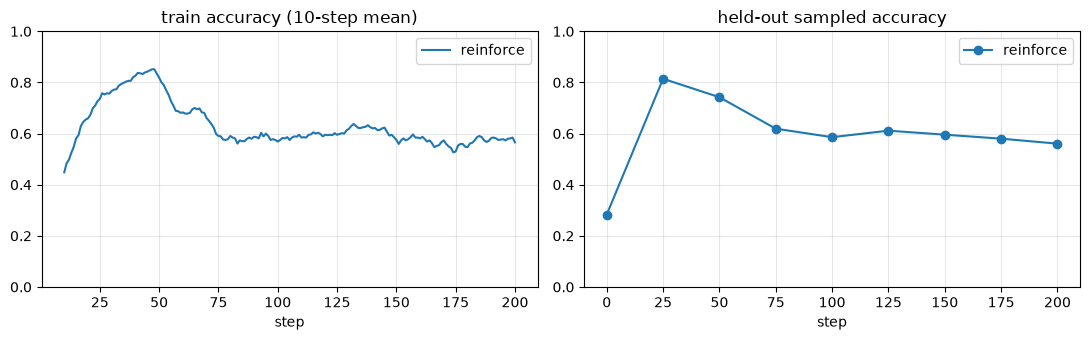

In [10]:
model_reinforce, RESULTS["reinforce"] = train("reinforce")
plot_runs(RESULTS)

In [11]:
seq = generate(model_reinforce, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))

#only completion:
comp = seq[:, ids.shape[1]:].tolist()

for name in range(6):
    print("sequence -> ", decode([c for c in seq[name] if c != PAD]))
    print("completion ids -> ", comp[name])
    print("completion -> ", decode(comp[name]))
    print()

sequence ->  <bos>ramya=aymar
completion ids ->  [4, 28, 16, 4, 21, 2]
completion ->  aymar

sequence ->  <bos>aniket=t
completion ids ->  [23, 2, 0, 0, 0, 0]
completion ->  t

sequence ->  <bos>daiwei=i
completion ids ->  [12, 2, 0, 0, 0, 0]
completion ->  i

sequence ->  <bos>reid=dier
completion ids ->  [7, 12, 8, 21, 2, 0]
completion ->  dier

sequence ->  <bos>gokcan=n
completion ids ->  [17, 2, 0, 0, 0, 0]
completion ->  n

sequence ->  <bos>haoyang=a
completion ids ->  [4, 2, 0, 0, 0, 0]
completion ->  a



🚨 Uh oh! It looks like the model has learned to emit early EOS tokens because it couldn't distinguish well between a small positive reward (0.5 just for EOS) and a larger positive reward (1.5 for correctness). How can we separate how good a specific action at each state is from the overall "quality" of that state itself?

*Hint*: Baselining!

### Ask the room
- Where does the gradient flow: through $\log\pi_\theta$, or through $\hat A_t$?
- Held-out accuracy climbs and then falls (on seed 0, 0.74 then 0.56; on about half the seeds overall). Why? Hint:
  what is $R(\tau)$ for a *wrong* answer that ends with `EOS`?

<details><summary><b>Answers</b></summary>

- **Gradient flow.** Only through $\log\pi_\theta$ (`log_probs`, computed by the current model with grad).
  $\hat A_t = R(\tau)$ is a number: the reward function scores sampled tokens, sampling is discrete, and
  `rollout` runs under `no_grad`. So the gradient of $-\hat A_t\log\pi_\theta$ is $-\hat A_t\nabla_\theta\log\pi_\theta$,
  exactly the score-function estimator. If the advantage did carry grad (say, from a critic that is being trained),
  it would have to be detached. That is why PPO builds $\hat A_t$ from the rollout-time values $V_{\phi_{\text{old}}}$.
- **Why it climbs, then falls.** A wrong answer that ends with `EOS` still gets $R(\tau) = 0.5$ (format bonus), so
  every sample gets $\Psi_t > 0$ and is pushed *up*. Only the size of the push (1.5 vs 0.5) separates right from
  wrong. The expected gradient is still correct, but each batch's estimate is dominated by "make whatever I
  sampled more likely": §8b measures about 2× the gradient noise of the baseline version. Our loop also takes 4
  minibatch steps per rollout with no ratio or clip, so the policy keeps sharpening onto its own samples, mistakes
  included. It ends about 4.9 nats from the base model, against about 1.2 for the runs that work (§8). The ablations
  in §8 (seeds 0–2) show the collapse needs both ingredients: setting `FORMAT_WEIGHT = 0` fixes it, and so does one
  on-policy step per rollout. These are the two problems the baseline (§5b) and PPO's clipped ratio (§6b) address.

</details>

### 5b. Add a baseline (1 line)
### Recap
Raw returns are noisy. Here every sample that terminates earns $R(\tau) \ge 0.5$, so $\Psi_t = R(\tau) > 0$ pushes
*every* sampled completion up, right or wrong; only the size of the push (1.5 vs 0.5) tells them apart. Subtract a
baseline:
$$\Psi_t = G_t - b(s_t)$$
It adds no bias for any $b$ that does not depend on the action $a_t$:
$$\mathbb{E}_{a_t\sim\pi_\theta(\cdot\mid s_t)}\big[\nabla_\theta\log\pi_\theta(a_t\mid s_t)\big]\, b(s_t) = b(s_t)\,\nabla_\theta\sum_a\pi_\theta(a\mid s_t) = b(s_t)\,\nabla_\theta 1 = 0$$
The simplest baseline is the mean over the $N$ rollouts in the batch:
$$b_\text{batch} = \frac{1}{N} \sum_{i=1}^{N} R(s_i, a_i), \qquad \hat{A}(s, a) = R(s, a) - b_\text{batch}$$
Subtlety: this mean includes the sample itself, which scales the expected gradient by $(N-1)/N$. A leave-one-out
mean removes that (RLOO, §9).

### In code
$R(s_i, a_i)$ is `rewards` (B, 1) with $N$ = B. Return $\hat A$ as (B, 1).

The rest of the session is about better baselines: PPO *learns* one per token, $V_\phi(s_t)$. GRPO uses the
other completions for the *same prompt*.

In [12]:
def compute_batch_mean_advantages(rewards):
    # print(rewards.shape) # (B,1)
    # print(rewards.mean(dim=0))
    return rewards - rewards.mean(dim=0) # R_t - b


check_close("batch-mean baseline", compute_batch_mean_advantages(torch.tensor([[1.5], [0.5], [0.5], [0.0]])),
            [[0.875], [-0.125], [-0.125], [-0.625]])

ok  batch-mean baseline


[reinforce_baseline] step   25  train reward 1.204  held-out acc 0.896  (2s)
[reinforce_baseline] step   50  train reward 1.405  held-out acc 0.936  (3s)
[reinforce_baseline] step   75  train reward 1.428  held-out acc 0.943  (5s)
[reinforce_baseline] step  100  train reward 1.419  held-out acc 0.912  (7s)
[reinforce_baseline] step  125  train reward 1.449  held-out acc 0.973  (9s)
[reinforce_baseline] step  150  train reward 1.471  held-out acc 0.980  (10s)
[reinforce_baseline] step  175  train reward 1.466  held-out acc 0.979  (12s)
[reinforce_baseline] step  200  train reward 1.479  held-out acc 0.986  (14s)


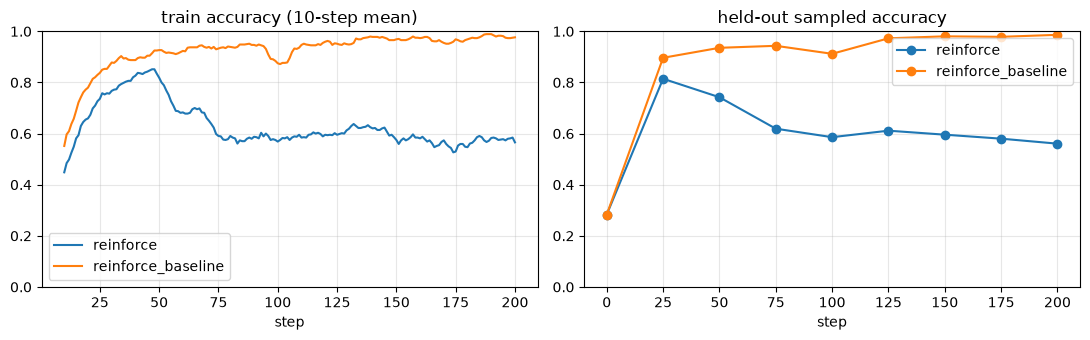

In [13]:
model_reinforce_baseline, RESULTS["reinforce_baseline"] = train("reinforce_baseline")
plot_runs(RESULTS)

In [14]:
test_batch = ["RAMYA", "ANIKET", "DAIWEI", "REID", "GOKCAN", "HAOYANG", "CHARAN", "EVELYN", "RHUSHIL"]
ids, mask = left_pad([encode_prompt(w.lower()) for w in test_batch])

seq = generate(model_reinforce_baseline, ids, mask, generator=torch.Generator(device=DEVICE).manual_seed(0))

#only completion:
comp = seq[:, ids.shape[1]:].tolist()

for name in range(5,9):
    print("sequence -> ", decode([c for c in seq[name] if c != PAD]))
    print("completion ids -> ", comp[name])
    print("completion -> ", decode(comp[name]))
    print()

sequence ->  <bos>haoyang=aahah
completion ids ->  [4, 4, 11, 4, 11, 2, 0]
completion ->  aahah

sequence ->  <bos>charan=narahc
completion ids ->  [17, 4, 21, 4, 11, 6, 2]
completion ->  narahc

sequence ->  <bos>evelyn=nyleve
completion ids ->  [17, 28, 15, 8, 25, 8, 2]
completion ->  nyleve

sequence ->  <bos>rhushil=hhr
completion ids ->  [11, 11, 21, 2, 0, 0, 0]
completion ->  hhr



## 6. PPO (≈15 min)
### Recap: what is still wrong with vanilla policy gradient
1. **No data reuse.** Rollouts are the expensive part, so our loop takes 4 minibatch steps per rollout batch. After the
   first step the samples come from $\pi_{\theta_{\text{old}}}$, not the current $\pi_\theta$, and the estimator is no
   longer the on-policy gradient. PPO's fix is the importance ratio, clipped to stay *proximal* to $\pi_{\theta_{\text{old}}}$ (6b).
2. **Noisy baselines.** A batch mean is one number for every state. PPO *learns* a critic $V_\phi(s_t)$ and gets
   per-token advantages with GAE (6a).

### 6a. Recap: TD residuals and GAE
The critic estimates $V^\pi(s_t) \triangleq \mathbb{E}[G_t \mid s_t]$. The TD residual is its one-step Bellman error,
the TD target minus the current prediction:
$$\delta_t^V = \tilde{r}_t + \gamma V_\phi(s_{t+1}) - V_\phi(s_t)$$
GAE is an exponentially weighted average of the $k$-step estimates, truncated at the end of the completion:
$$\hat{A}_t^{GAE} = \sum_{l=0}^{T-t-1} (\gamma\lambda)^l\,\delta_{t+l}^V \qquad\Longleftrightarrow\qquad \hat A_t = \delta_t^V + \gamma\lambda\,\hat A_{t+1}\ \text{(computed backwards)}$$

| $\lambda$ | $\hat A_t$ | Bias | Variance |
| --- | --- | --- | --- |
| 0 | $\delta_t^V$ (1-step TD) | high if the critic is wrong | low |
| 1 | $G_t - V_\phi(s_t)$ (Monte Carlo) | no critic-induced bias | high |

The KL-shaped reward is $\tilde r_t = -\beta KL_t$, plus $R(\tau)$ at $t = T-1$. With $\beta = 0$ (the book's config)
that is $\tilde r_t = 0$ except $\tilde r_{T-1} = R(\tau)$. After the last token there is no next state, so $V_\phi(s_T) = 0$.

### In code
| Math | Code |
| --- | --- |
| $\tilde r_t$ | build it (B, S-1) from `rewards` (B, 1): $R(\tau)$ at the **last action index**, 0 elsewhere |
| $V_\phi(s_t)$ | `values` (B, S-1), the critic at rollout time |
| $t = 0,\dots,T-1$ | positions where `action_mask` is True. With left padding, the last action index differs per row |
| $V_\phi(s_T) = 0$ | a done flag $d_t = 1$ at and after the last action: $\delta_t^V = \tilde r_t + \gamma(1-d_t)V_\phi(s_{t+1}) - V_\phi(s_t)$ and $\hat A_t = \delta_t^V + \gamma\lambda(1-d_t)\hat A_{t+1}$ |

**Write `compute_gae`.** Return $\hat A_t$ as (B, S-1), zeroed outside `action_mask`. Hints: the last action index is
`action_mask.long().cumsum(-1).argmax(-1, keepdim=True)`; use `scatter_` to place $R(\tau)$ there.

**Why `not_done` ($1 - d_t$)?** The loop walks backwards over every column for the whole batch, but each row's
completion ends at a different column. Any `PAD` columns after the last action still have critic values, and the loop
reaches them first. At the last action, $d_t = 1$ zeroes two things that came from that padding:
- `next_value`, the critic at a `PAD`. Zeroing it bootstraps with $V_\phi(s_T) = 0$, so the last token gets
  $\delta = R(\tau) - V_\phi(s_{T-1})$.
- `running`, the advantage accumulated over the `PAD`s. Zeroing it restarts the sum at the true end of the episode.

If you drop either one, row 1 of the checks comes out wrong: it has two `PAD`s after its last action. Row 0 ends at
the final column, so it passes either way. `not_done` doesn't mask anything itself: `PAD` and prompt columns still get
values, and `* action_mask` at the end zeroes them. In a classic RL buffer with episodes stored back to back, the same
$(1 - d_t)$ stops the next episode's values from leaking into this one.

In [16]:
# GAE is a bit difficult to wrap your head around. I recommend uncommenting the print statements and checking your understanding of what each variable is at each step.

def compute_gae(rewards, action_mask, values, gamma, lam):
    """rewards (B, 1), action_mask (B, T) bool, values (B, T). Returns advantages (B, T), 0 off-mask."""
    # print(rewards.shape, action_mask.shape, values.shape)
    B, S = action_mask.shape
    last = action_mask.long().cumsum(dim=-1).argmax(dim=-1, keepdim=True)
    # R(tau) goes at each row's last action, not column S-1: rows that end early have PADs after EOS.
    r = torch.zeros(B, S, device=rewards.device).scatter_(-1, last, rewards.float())
    done = (torch.arange(S, device=action_mask.device)[None] >= last).float()
    advantages = torch.zeros(B, S, device=action_mask.device)
    next_value = torch.zeros(B, device=action_mask.device)
    running = torch.zeros(B, device=action_mask.device)
    # print("delta = r + (1-done) * gamma * next_value - values")
    for t in reversed(range(S)):
        not_done = 1.0 - done[:, t]
        # print(not_done)
        delta = r[:, t] + not_done * gamma * next_value - values[:, t]
        running = delta + not_done * gamma * lam * running
        # print("delta_",t,"=", delta, "=",r[:, t], "+", not_done, "*", gamma, "*", next_value, "-", values[:, t])
        advantages[:, t] = running
        next_value = values[:, t]
    # print(advantages)
    # print()
    return advantages * action_mask


# row 0: 2 prompt positions then 3 actions; row 1: 1 prompt position, 2 actions, 2 pads
am = torch.tensor([[False, False, True, True, True], [False, True, True, False, False]])
V = torch.tensor([[0.9, 0.8, 0.5, 0.6, 0.4], [0.7, 0.2, 0.3, 0.9, 0.9]])
R = torch.tensor([[1.0], [0.0]])
check_close("GAE lam=1, gamma=1 -> R - V_t on actions", compute_gae(R, am, V, 1.0, 1.0),
            [[0, 0, 0.5, 0.4, 0.6], [0, -0.2, -0.3, 0, 0]])
check_close("GAE lam=0 -> one-step TD residual", compute_gae(R, am, V, 1.0, 0.0),
            [[0, 0, 0.1, -0.2, 0.6], [0, 0.1, -0.3, 0, 0]])
# row 0: A4 = 1-0.4 = 0.6; A3 = (0.9*0.4-0.6) + 0.45*0.6 = 0.03; A2 = (0.9*0.6-0.5) + 0.45*0.03 = 0.0535
# row 1: A2 = 0-0.3 = -0.3; A1 = (0.9*0.3-0.2) + 0.45*(-0.3) = -0.065
check_close("GAE gamma=0.9, lam=0.5 (hand computed)", compute_gae(R, am, V, 0.9, 0.5),
            [[0, 0, 0.0535, 0.03, 0.6], [0, -0.065, -0.3, 0, 0]], atol=1e-6)

ok  GAE lam=1, gamma=1 -> R - V_t on actions
ok  GAE lam=0 -> one-step TD residual
ok  GAE gamma=0.9, lam=0.5 (hand computed)


*Ask the room:* the first two checks are $\lambda = 1$ and $\lambda = 0$. Read the table above off them. Why does the
book use $\gamma = 1$, $\lambda = 0.98$ for LLMs?

<details><summary><b>Answers</b></summary>

- **$\lambda = 1$** (first check): $\hat A_t = G_t - V_\phi(s_t) = R(\tau) - V_\phi(s_t)$ on every action token. Row 0:
  $1 - [0.5, 0.6, 0.4] = [0.5, 0.4, 0.6]$. This is the Monte Carlo advantage: the real reward everywhere and no
  critic-induced bias, but high variance.
- **$\lambda = 0$** (second check): $\hat A_t = \delta_t^V$. On intermediate tokens that is
  $V_\phi(s_{t+1}) - V_\phi(s_t)$ (row 0: $0.6-0.5 = 0.1$ and $0.4-0.6 = -0.2$), which is pure critic. Only the last
  token sees the reward: $1 - 0.4 = 0.6$. Low variance, but it is only as good as the critic.
- **Why $\gamma = 1$:** the horizon is finite and the reward is terminal and judges the whole sequence. Discounting
  would just give early tokens less credit for an outcome they helped decide.
- **Why $\lambda = 0.98$:** it stays close to Monte Carlo because an LLM critic is hard to train and starts out
  untrained (only its head is new). A little bootstrapping still trims variance on long completions. Here
  completions are about 5 tokens and $0.98^5 \approx 0.9$, so it is nearly Monte Carlo.

</details>

### 6b. Recap: the clipped surrogate and the critic loss
The importance ratio asks how much more or less likely token $a_t$ is now than under the policy that sampled it:
$$\rho_t(\theta) \triangleq \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_{\text{old}}}(a_t \mid s_t)}$$
$L^{CPI} = \mathbb{E}_t[\rho_t \hat A_t]$ has the policy gradient as its gradient at $\rho_t = 1$, but grows without
bound as $\rho_t$ grows. PPO clips the ratio to a trust region around 1 and takes the pessimistic minimum:
$$J_{\text{PPO}}(\theta) = L^{CLIP}(\theta) \triangleq \mathbb{E}_t \left[\min\left( \rho_t \hat{A}_t,\ \text{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\, \hat{A}_t \right) \right]$$

| | $\rho_t < 1-\epsilon$ | $1-\epsilon \le \rho_t \le 1+\epsilon$ | $\rho_t > 1+\epsilon$ |
| --- | --- | --- | --- |
| $\hat A_t > 0$ | $\rho_t\hat A_t$: push up (**reinforce**) | $\rho_t\hat A_t$ | $(1+\epsilon)\hat A_t$: **clipped**, zero gradient |
| $\hat A_t < 0$ | $(1-\epsilon)\hat A_t$: **clipped**, zero gradient | $\rho_t\hat A_t$ | $\rho_t\hat A_t$: push down (**suppress**) |

Clipping stops a move once $\pi_\theta$ has gone far enough in the good direction, and never blocks a correction.

The **critic** regresses on the value target $\hat V_t = \hat A_t^{GAE} + V_{\phi_{\text{old}}}(s_t)$:
$$\mathcal{L}_{V} = \tfrac{1}{2}\left(V_\phi(s_t)-\hat V_t\right)^2$$
clipped the same way. Let $V^{clip} = \text{clip}\big(V_\phi(s_t),\ V_{\phi_{\text{old}}}(s_t)-\epsilon_V,\ V_{\phi_{\text{old}}}(s_t)+\epsilon_V\big)$,
and take the max of the clipped and unclipped losses.

The total, minimized: $-L^{CLIP}(\theta) + c_1\,\mathcal{L}_V$. The PPO paper also adds an entropy bonus $c_2 S[\pi_\theta]$,
which LLM implementations usually leave off.

### In code
| Math | Code |
| --- | --- |
| $\rho_t$ | `(log_probs - experience.log_probs_old).exp()` |
| $\hat A_t$ | `experience.advantages` (B, S-1), from `compute_gae` |
| $V_\phi(s_t)$, $V_{\phi_{\text{old}}}(s_t)$ | `values` (has grad), `experience.values_old` |
| $\epsilon$, $\epsilon_V$, $c_1$ | `clip_eps_lo` / `clip_eps_hi` (0.2), `clip_eps_val` (0.4), `vf_coef` (0.5) |
| $\mathbb{E}_t$ | `masked_mean(dim=-1)` over each sequence's tokens, then `.mean(0)` |

**Write `PPOLoss.forward`.** Per token: $-\min(\cdot) + c_1\mathcal{L}_V$, then reduce as before. The code allows
asymmetric bounds $[1-\epsilon_{lo}, 1+\epsilon_{hi}]$; both are 0.2 here.

In [17]:
class PPOLoss(nn.Module):
    def __init__(self, clip_eps_lo, clip_eps_hi, clip_eps_val, vf_coef, **kwargs):
        super().__init__()
        self.clip_eps_lo, self.clip_eps_hi = clip_eps_lo, clip_eps_hi
        self.clip_eps_val, self.vf_coef = clip_eps_val, vf_coef

    def forward(self, log_probs, experience, values, **kwargs):
        value_targets = experience.advantages + experience.values_old  # value target V̂_t = Â_t + V_φold(s_t)
        values_clipped = torch.clamp(values, experience.values_old - self.clip_eps_val,
                                     experience.values_old + self.clip_eps_val)
        value_fn_loss = torch.max(0.5 * (value_targets - values) ** 2, 0.5 * (value_targets - values_clipped) ** 2)

        ratio = (log_probs - experience.log_probs_old).exp()  # ρ_t
        unclipped = ratio * experience.advantages
        clipped = ratio.clamp(1 - self.clip_eps_lo, 1 + self.clip_eps_hi) * experience.advantages
        policy_loss = -torch.min(unclipped, clipped)  # -L^CLIP per token

        loss = policy_loss + self.vf_coef * value_fn_loss
        return masked_mean(loss, mask=experience.action_mask, dim=-1).mean(dim=0)


# check: one sequence, 4 action tokens covering the four clip cases (eps = 0.2), plus a masked position
ratio = torch.tensor([[1.5, 0.5, 0.5, 1.5, 3.0]])
old = torch.tensor([[-1.0, -2.0, -0.5, -1.2, -0.3]])
lp = (old + ratio.log()).requires_grad_()
ex = Experience(sequence_ids=None, attention_mask=None, rewards=None, log_probs_old=old,
                action_mask=torch.tensor([[True, True, True, True, False]]),
                advantages=torch.tensor([[1.0, 1.0, -1.0, -1.0, 5.0]]),
                values_old=torch.tensor([[0.1, 0.0, -0.2, 0.3, 0.0]]))
v = torch.tensor([[0.5, -0.1, 0.0, 0.0, 0.0]], requires_grad=True)
ppo = PPOLoss(clip_eps_lo=0.2, clip_eps_hi=0.2, clip_eps_val=0.2, vf_coef=0.0)
l = ppo(lp, ex, values=v)
check_close("PPO policy loss (4 clip cases)", l, (-1.2 - 0.5 + 0.8 + 1.5) / 4)
l.backward()
check_close("PPO policy grad: 0 where clipped", lp.grad, [[0.0, -0.125, 0.0, 0.375, 0.0]])
ppo.vf_coef, v.grad = 1.0, None
l_v = ppo(old.clone(), ex, values=v)
# At ratio 1 the policy part is -mean(A) = 0. Targets V̂ = A + V_old = [1.1, 1.0, -1.2, -0.7]; V clipped to V_old ± 0.2.
# t0: V 0.5 -> 0.3: max(0.5*0.6^2, 0.5*0.8^2) = 0.32   t1: V -0.1 (inside): 0.5*1.1^2 = 0.605
# t2: V 0.0 (inside): 0.5*1.2^2 = 0.72                  t3: V 0.0 -> 0.1: max(0.5*0.7^2, 0.5*0.8^2) = 0.32
check_close("PPO value loss (clipped, max)", l_v, (0.32 + 0.605 + 0.72 + 0.32) / 4)

ok  PPO policy loss (4 clip cases)
ok  PPO policy grad: 0 where clipped
ok  PPO value loss (clipped, max)


[ppo] step   25  train reward 1.171  held-out acc 0.861  (3s)
[ppo] step   50  train reward 1.392  held-out acc 0.924  (6s)
[ppo] step   75  train reward 1.428  held-out acc 0.953  (9s)
[ppo] step  100  train reward 1.450  held-out acc 0.971  (12s)
[ppo] step  125  train reward 1.468  held-out acc 0.973  (15s)
[ppo] step  150  train reward 1.482  held-out acc 0.975  (18s)
[ppo] step  175  train reward 1.476  held-out acc 0.980  (21s)
[ppo] step  200  train reward 1.480  held-out acc 0.979  (24s)


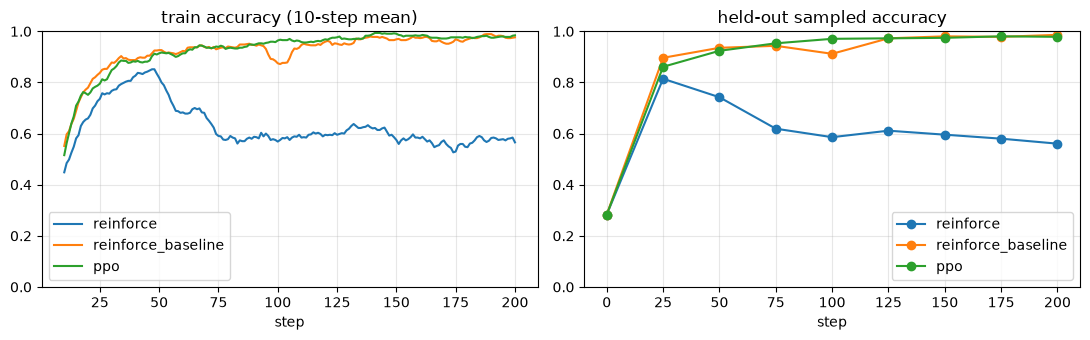

In [18]:
model_ppo, RESULTS["ppo"] = train("ppo")
plot_runs(RESULTS)

### Ask the room
- Walk the clip table: in the check above, which tokens got zero gradient, and why?
- Why `max` for the value loss?
- RLHF with PPO keeps four models: $\pi_\theta$, $V_\phi$, $\pi_{\text{ref}}$, $r_\psi$. Which are in memory here?
  ($\pi_\theta$ and $V_\phi$. The reward is a function, and $\pi_{\text{ref}}$ is needed only if $\beta > 0$.)
- Two anchors: clipping keeps $\pi_\theta$ near $\pi_{\theta_{\text{old}}}$ (refreshed every batch). The KL keeps it
  near the fixed $\pi_{\text{ref}}$. Does clipping bound how far the policy moves in one batch?

<details><summary><b>Answers</b></summary>

- **Clip table, from the check:** $\rho = [1.5, 0.5, 0.5, 1.5]$, $\hat A = [1, 1, -1, -1]$, $\epsilon = 0.2$.
  The gradient on `log_probs` was $[0, -0.125, 0, 0.375]$ (each is $-\rho_t\hat A_t / 4$ when unclipped):
  - token 0: $\hat A>0$, $\rho>1+\epsilon$: already pushed up enough, so it is **clipped** and the gradient is 0.
  - token 1: $\hat A>0$, $\rho<1-\epsilon$: the min picks $\rho\hat A$, so the gradient keeps pushing it up.
  - token 2: $\hat A<0$, $\rho<1-\epsilon$: already pushed down enough, so it is **clipped** and the gradient is 0.
  - token 3: $\hat A<0$, $\rho>1+\epsilon$: moved the wrong way, so the min picks $\rho\hat A$ and pushes it down.
  - token 4 ($\rho = 3$, $\hat A = 5$) is padding: `action_mask` zeroes it whatever its values.
- **Why `max` for the value loss:** it is pessimistic, like the `min` in the policy objective. If $V_\phi$ has left
  the $\pm\epsilon_V$ band by moving *toward* $\hat V_t$, the clipped term (constant, no gradient) is the larger one,
  so updates stop. If it has left the band *away* from $\hat V_t$, the unclipped term is larger and still corrects
  it. So clipping can only remove the incentive to move far in one batch; it never blocks a correction. Ablation
  studies found value clipping often doesn't help (Engstrom et al., 2020; Andrychowicz et al., 2021), so treat it as
  optional.
- **Models in memory:** $\pi_\theta$ and $V_\phi$ only. $\pi_{\theta_{\text{old}}}$ is not a separate model: its
  log-probs are cached at rollout time (`log_probs_old`). Here $V_\phi$ is a full copy of the policy with a new
  head (`get_val_model`), which is the 2× trained parameters in the §8 table. At scale it is often a separate,
  sometimes smaller, model, or a value head on the policy's backbone.
- **Does clipping bound the drift?** No. It is a soft trust region:
  - The parameters are shared, so updates driven by other tokens can push any token's $\rho_t$ out of the band.
  - Tokens where the min picks the unclipped term keep receiving gradient beyond the band.
  - It only looks at sampled tokens; probability mass on unsampled tokens moves freely.

  That is why implementations log the clip fraction and the approximate KL to $\pi_{\theta_{\text{old}}}$, and some
  stop the epoch early when the KL passes a target.

</details>

## 7. GRPO (≈10 min)
### 7a. Recap: group-relative advantages
Drop $V_\phi$ entirely and use group statistics as the baseline. For each prompt $s$, sample a group of $G$
completions $\{a_1, \dots, a_G\}$ from $\pi_{\theta_{\text{old}}}$ and score each, $R_i = R(s, a_i)$. The advantage is a
$z$-score within the group:
$$\hat{A}_i = \frac{R_i - \text{mean}(R_1, \dots, R_G)}{\text{std}(R_1, \dots, R_G)}$$
- As in REINFORCE and RLOO, the single scalar $\hat A_i$ is broadcast to every token of completion $i$.
- Hard prompts get a low group mean, so the baseline adapts to prompt difficulty (like RLOO's $K$ completions).
- If every completion in a group gets the same reward, then $\hat A_i = 0$ (a small constant is added to the std):
  no learning signal from that group.

### In code
| Math | Code |
| --- | --- |
| $R_i$ | `rewards` (B, 1) in prompt-major order (each group's $G$ siblings are adjacent), B = prompts × $G$ |
| $G$ | `num_rollouts` |
| $\text{std}$ | unbiased (`torch.std` default), plus `eps` = 1e-8, as in `utils.compute_standardized_advantages` |

**Write `compute_standardized_advantages`.** Return $\hat A_i$ as (B, 1).

In [19]:
def compute_standardized_advantages(rewards, num_rollouts, eps=1e-8):
    r = rewards.view(-1, num_rollouts)
    # print(r.shape)
    advantages = ((r - r.mean(dim=1, keepdim=True)) / (r.std(dim=1, keepdim=True) + eps)).view(-1, 1)
    # print(advantages)
    return advantages


rw = torch.tensor([1.0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1])[:, None]
s3 = 3 ** 0.5 / 2
check_close("GRPO advantages, G=4", compute_standardized_advantages(rw, 4),
            torch.tensor([1.5, -0.5, -0.5, -0.5, 0, 0, 0, 0, -s3, s3, -s3, s3])[:, None])

ok  GRPO advantages, G=4


### 7b. Recap: the GRPO objective
Combine the group-relative advantage with PPO's per-token ratio and clipping, and put the KL penalty **in the
objective** (PPO-RLHF puts it in the reward):
$$J_{\text{GRPO}}(\theta) = \frac{1}{G}\sum_{i=1}^{G} \frac{1}{|a_i|}\sum_{t=1}^{|a_i|} \left( \min\left( \rho_{i,t} \hat{A}_i,\ \text{clip}(\rho_{i,t}, 1-\epsilon, 1+\epsilon)\,\hat{A}_i \right) - \beta \, \widehat D_{\mathrm{KL},i,t} \right)$$
- Per-token ratio: $\rho_{i,t} = \dfrac{\pi_\theta(a_{i,t} \mid s_{i,t})}{\pi_{\theta_{\text{old}}}(a_{i,t} \mid s_{i,t})}$, where $s_{i,t}$ is the prompt plus $a_{i,<t}$.
- The KL estimate is Schulman's $k_3$. It is unbiased for $D_{\mathrm{KL}}(\pi_\theta\,\|\,\pi_{\text{ref}})$ under samples from $\pi_\theta$, and never negative:
$$\widehat D_{\mathrm{KL},i,t} = \frac{\pi_{\mathrm{ref}}(a_{i,t}\mid s_{i,t})}{\pi_\theta(a_{i,t}\mid s_{i,t})} - \log\frac{\pi_{\mathrm{ref}}(a_{i,t}\mid s_{i,t})}{\pi_\theta(a_{i,t}\mid s_{i,t})} - 1$$
- Many later recipes set $\beta = 0$ and drop $\pi_{\text{ref}}$; so do the book's configs.
- DeepSeekMath took one update per batch, so there $\rho_{i,t} = 1$. Our 4 minibatch steps make the clip matter.

### In code
| Math | Code |
| --- | --- |
| $\rho_{i,t}$ | `(log_probs - experience.log_probs_old).exp()` |
| $\hat A_i$ | `experience.advantages` (B, 1) |
| $\widehat D_{\mathrm{KL},i,t}$ | with $x = \log\pi_{\text{ref}} - \log\pi_\theta$ (masked): $e^{x} - x - 1$, i.e. `torch.expm1(x) - x` |
| $\frac{1}{\lvert a_i\rvert}\sum_{t}$ | `masked_mean(dim=-1)` |
| $\frac{1}{G}\sum_{i}$ | `.mean(0)` over every completion in the minibatch |

**Write `GRPOLoss.forward`.** It minimizes $-J_{\text{GRPO}}$. Skip the KL entirely when `beta == 0`;
`log_probs_ref` is `None` then.

In [20]:
class GRPOLoss(nn.Module):
    def __init__(self, clip_eps_lo, clip_eps_hi, beta, **kwargs):
        super().__init__()
        self.clip_eps_lo, self.clip_eps_hi, self.beta = clip_eps_lo, clip_eps_hi, beta

    def forward(self, log_probs, experience, **kwargs):
        ratio = (log_probs - experience.log_probs_old).exp()  # ρ_{i,t}
        unclipped = ratio * experience.advantages
        clipped = ratio.clamp(1 - self.clip_eps_lo, 1 + self.clip_eps_hi) * experience.advantages
        loss = -torch.min(unclipped, clipped)
        # add KL penalty directly to loss if beta != 0
        if self.beta:
            log_ratio = (experience.log_probs_ref - log_probs) * experience.action_mask  # log(π_ref / π_θ)
            loss = loss + self.beta * (torch.expm1(log_ratio) - log_ratio)  # + β·D̂_KL (k3)
        return masked_mean(loss, mask=experience.action_mask, dim=-1).mean(dim=0)



old = torch.tensor([[-1.0, -2.0, -0.5], [-0.3, -0.7, -9.0]])
ex = Experience(sequence_ids=None, attention_mask=None, rewards=None, log_probs_old=old,
                action_mask=torch.tensor([[True, True, True], [True, True, False]]),
                advantages=torch.tensor([[1.0], [-2.0]]), log_probs_ref=old - torch.tensor([[0.5, 0, 0], [0, 0, 0]]))
lp = old.clone().requires_grad_()
l = GRPOLoss(clip_eps_lo=0.2, clip_eps_hi=0.2, beta=0.0)(lp, ex)
check_close("GRPO on-policy loss = -mean(A)", l, (-1.0 + 2.0) / 2)
l.backward()
check_close("GRPO on-policy grad = -A / (n_tokens * B)", lp.grad, [[-1 / 6, -1 / 6, -1 / 6], [0.5, 0.5, 0.0]])
k3 = torch.tensor(-0.5).exp() - 1 + 0.5
check_close("GRPO + k3 KL (beta=0.1)", GRPOLoss(clip_eps_lo=0.2, clip_eps_hi=0.2, beta=0.1)(old, ex),
            0.5 + 0.1 * k3 / 3 / 2)
ex.advantages = torch.tensor([[1.0], [1.0]])
check_close("GRPO clips (ratio 1.5, A>0)", GRPOLoss(clip_eps_lo=0.2, clip_eps_hi=0.2, beta=0.0)(old + 0.405465, ex),
            -1.2)

ok  GRPO on-policy loss = -mean(A)
ok  GRPO on-policy grad = -A / (n_tokens * B)
ok  GRPO + k3 KL (beta=0.1)
ok  GRPO clips (ratio 1.5, A>0)


[grpo] step   25  train reward 1.213  held-out acc 0.869  dead groups 0.17  (2s)
[grpo] step   50  train reward 1.387  held-out acc 0.934  dead groups 0.41  (4s)
[grpo] step   75  train reward 1.427  held-out acc 0.959  dead groups 0.56  (5s)
[grpo] step  100  train reward 1.467  held-out acc 0.969  dead groups 0.76  (7s)
[grpo] step  125  train reward 1.476  held-out acc 0.973  dead groups 0.82  (9s)
[grpo] step  150  train reward 1.469  held-out acc 0.980  dead groups 0.79  (11s)
[grpo] step  175  train reward 1.482  held-out acc 0.984  dead groups 0.86  (13s)
[grpo] step  200  train reward 1.481  held-out acc 0.980  dead groups 0.88  (14s)


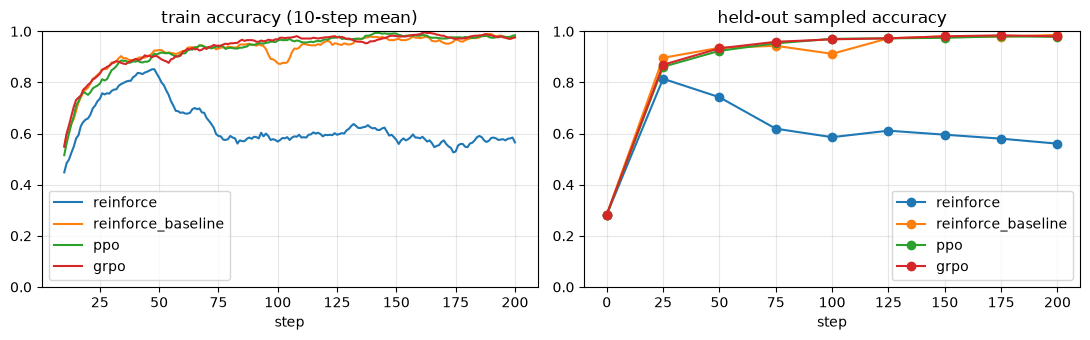

In [21]:
model_grpo, RESULTS["grpo"] = train("grpo")
plot_runs(RESULTS)

### Ask the room
- What gradient does a group with all-equal rewards give? Watch the "dead groups" column above climb as accuracy rises.
- $\frac{1}{|a_i|}$ weights every completion equally whatever its length. Who pays: long correct answers or long
  wrong ones? DAPO averages over all tokens instead; Dr. GRPO divides by a constant.
- Why do the book's configs ship with $\beta = 0$?

<details><summary><b>Answers</b></summary>

- **All-equal group:** the numerator $R_i - \text{mean}$ is 0 for every $i$ (the small constant keeps the
  denominator finite), so $\hat A_i = 0$. There is no policy gradient, only the KL term if $\beta > 0$, and the $G$
  generations were wasted. With per-sample accuracy $p$, a group is dead with probability $p^G + (1-p)^G$, which goes
  to 1 as the policy improves. Here about 85–90% of groups are dead by step 200, so GRPO's effective batch *shrinks
  as it succeeds*. DAPO's dynamic sampling drops these groups and samples more prompts to refill the batch.
- **Length weighting:** under $\frac{1}{|a_i|}$, each token's weight is inversely proportional to its completion's
  length. A long *wrong* answer spreads its negative $\hat A_i$ over many tokens, so each token is penalized less.
  A short correct answer gets a bigger per-token push. The net effect nudges wrong answers to grow longer (Dr. GRPO's
  response-level length bias). DAPO averages over every token in the group ($\frac{1}{\sum_i |a_i|}$), so all tokens
  weigh the same. Dr. GRPO sums and divides by a constant (e.g. the generation budget). In this toy the completion
  length is fixed by the word (3–6 letters + `EOS`), so the effect is small here.
- **Why $\beta = 0$:** with a verifiable reward (an exact-match checker) there is no learned reward model to
  exploit, so the anchor to $\pi_{\text{ref}}$ matters less. The KL term also slows learning: in §8, $\beta = 0.05$
  ends at 0.95–0.97 against 0.98–0.99 without it. Dropping $\pi_{\text{ref}}$ saves a model in memory and a forward
  pass per batch. Clipping still keeps each update close to $\pi_{\theta_{\text{old}}}$. DAPO and Dr. GRPO drop the KL,
  and TRL's `GRPOTrainer` defaults to `beta=0.0`.

</details>

## 8. Compare (≈3 min)

| | REINFORCE (+ baseline) | PPO | GRPO |
| --- | --- | --- | --- |
| Advantage | $\hat A = R(\tau)$ (§5); $R_k - \text{mean}(R_\text{batch})$ (§5b) | $\hat A_t = \sum_{l=0}^{T-t-1}(\gamma\lambda)^l\delta_{t+l}^V$ (GAE) | $\hat A_i = \dfrac{R_i - \mu_G}{\sigma_G}$ |
| Granularity | sequence | token ($t$) | sequence ($i$) |
| Update style | unconstrained | clipped IS ratio $\rho_t$ | clipped IS ratio $\rho_{i,t}$ |
| Models in memory (RLHF) | 3: $\pi_\theta, \pi_{\text{ref}}, r_\psi$ | 4: $\pi_\theta, V_\phi, \pi_{\text{ref}}, r_\psi$ | 3, or fewer with $\beta = 0$ (no $\pi_{\text{ref}}$) or a verifier (no $r_\psi$) |
| Models in memory here | $\pi_\theta$ | $\pi_\theta, V_\phi$ | $\pi_\theta$ |
| KL penalty | optional, in the reward | in the reward ($\tilde r_t$) | in the loss ($k_3$), often dropped |
| Samples per prompt | 1 | 1 | $G$ (8 here) |

**What to expect.** Runs are deterministic on a given machine, so seed 0 on an RTX 3090 reproduces the
saved outputs in this notebook. Other hardware will give different, similar-looking curves. Held-out accuracy
after the default 200 steps, from a base model at ≈ 0.26–0.31:
- **REINFORCE, no baseline:** climbs as fast as the others at first, then degrades on half the seeds: 4 of 8 are
  below 0.6 at step 200, and 6 of 8 are well below their peak by step 300. Seed 0 peaks at 0.74 around step 50 and
  ends at 0.56.
- **REINFORCE + batch-mean baseline (§5b):** 0.98–0.99 on all 8 seeds (0.97–0.99 at step 300).
- **PPO:** 0.92–0.99 over 8 seeds (0.98–0.99 at step 300), with brief dips on 2 of 8 seeds that recover.
- **GRPO:** 0.98–0.99 over 8 seeds. As accuracy rises more groups are "dead" (all $G$ rewards equal, so
  $\hat A_i = 0$ and no gradient): about 85–90% of them over the last 25 steps (seeds 0–2). With 16 prompts × 4
  rollouts: 0.97–0.98. With $\beta = 0.05$: 0.95–0.97 (seeds 0–2).
- **RLOO / Dr. GRPO (§9):** 0.94–0.98 / 0.96–0.98 (seeds 0–2).

**So how do they differ, if not in final accuracy?** That is the table under the plot. Seeds 0–3 unless noted:
- **Steps to 90% train accuracy** (sample efficiency; every method uses 64 completions per step): batch-mean
  baseline 34–45, GRPO 37–50 (8 seeds), PPO 43–54. The gaps are about the size of the seed-to-seed spread, so treat
  this as "all similar", not a ranking. REINFORCE without a baseline reaches 90% on some seeds (38–46 steps) and
  then may still collapse, so this column can't show its failure.
- **Cost:** PPO trains twice the parameters (the critic $V_\phi$) and takes 1.5–2× the time per step. The others
  cost the same. At LLM scale that is the "models in memory" row of the table above.
- **KL to base** $D_{\mathrm{KL}}(\pi_\theta\,\|\,\pi_{\text{base}})$, per sequence: runs that end near 0.98 accuracy land at
  1.15–1.22 nats, roughly what it costs to turn the base model into a near-deterministic correct speller (a run
  caught mid-dip, PPO seed 3 at 0.92, sits at 1.4). Collapsed REINFORCE runs end at about 5 nats: they moved four
  times further and got *worse*. So this column flags a failure; it doesn't rank the methods that work.
- **Gradient noise (§8b), the clearest difference.** At the base model, a baseline roughly halves the gradient's
  noise-to-signal ratio (relative variance 2.8–3.6 → 1.5–1.9; seeds 0–4), and independent batches agree about twice
  as well (cosine 0.19–0.24 → 0.34–0.40). Per-prompt baselines (RLOO, GRPO) don't beat the batch mean here: the
  words are all about equally hard, so a per-prompt baseline gains little and is estimated from only 7 other
  samples. They should win when prompt difficulty varies a lot.

The takeaway matches the writeup's summary: on this task, once there is a baseline, the algorithm choice mostly
changes stability and cost, not the result.

Ablations on REINFORCE without a baseline (seeds 0–2, 200 steps). Removing the +0.5 format bonus fixes it (0.996). So
does one on-policy step per rollout instead of four minibatch steps (0.97). On these seeds the collapse needs
**both** the constant reward offset with no baseline **and** repeated unclipped updates on the same rollout. Those are
the two problems that baselines and PPO's clipped ratio address. These are one toy and a few seeds: illustrations,
not a benchmark.

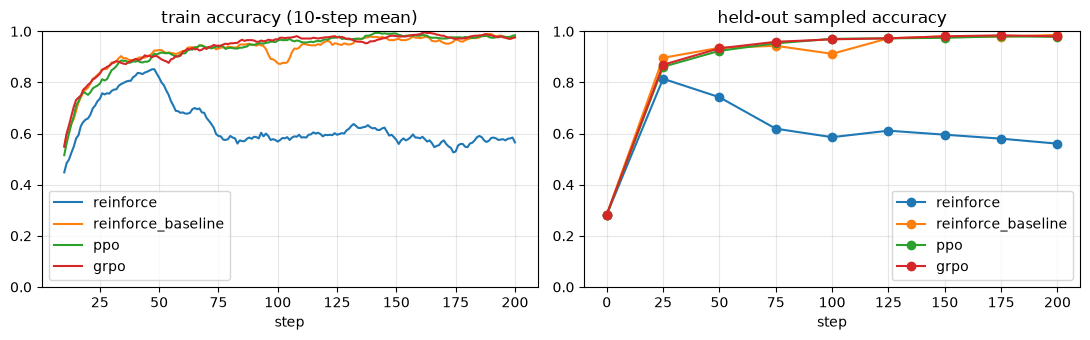

run                  final acc steps to 90%  ms/step  trained params  KL to base
reinforce                0.561            —       68         408,576        4.88
reinforce_baseline       0.986           34       68         408,576        1.18
ppo                      0.979           47      118         813,440        1.17
grpo                     0.980           44       71         408,576        1.17


In [22]:
def steps_to(h, target=0.9, k=10):
    """First step at which the k-step mean train accuracy reaches target (None if never)."""
    smooth = torch.tensor(h["train_acc"]).unfold(0, k, 1).mean(-1)
    hit = (smooth >= target).nonzero()
    return int(hit[0]) + k if len(hit) else None


def summarize(results, target=0.9):
    print(f"{'run':20s} {'final acc':>9s} {'steps to ' + format(target, '.0%'):>12s} {'ms/step':>8s} "
          f"{'trained params':>15s} {'KL to base':>11s}")
    for name, h in results.items():
        s = steps_to(h, target)
        print(f"{name:20s} {h['eval_acc'][-1]:9.3f} {s if s else '—':>12} {1e3 * h['train_seconds'] / len(h['reward']):8.0f} "
              f"{h['train_params']:15,d} {h['kl_to_base']:11.2f}")


plot_runs(RESULTS)
summarize(RESULTS)

### 8b. Gradient noise: the variance argument, measured
Every method estimates the same $\nabla_\theta J(\theta)=\mathbb{E}\big[\sum_t \Psi_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)\big]$
and differs mainly in $\Psi_t$. So hold the samples fixed and change only $\Psi_t$. Take the base model and draw 32
independent batches (8 prompts × 8 completions). On each batch, compute the gradient $\hat g$ under each advantage
estimator. On-policy ($\rho = 1$) the clipped PPO/GRPO losses have the same gradient as `ReinforceLoss`, so one loss
serves for all. Two numbers per estimator:
- **relative variance** $\mathbb{E}\|\hat g - \bar g\|^2 / \|\bar g\|^2$: the gradient's noise-to-signal ratio. Roughly how many
  batches you would need to average before the signal outweighs the noise.
- **mean pairwise cosine** between batch gradients: do two independent batches agree on which way to step?

PPO is left out because its advantage depends on the critic, which is untrained at the base model. GRPO's division by
$\sigma_G$ also changes *which* direction is estimated (Dr. GRPO's point), so lower noise there does not mean the
same target.

In [23]:
def gradient_noise(n_batches=32, num_prompts=8, G=8, seed=0):
    seed_everything(seed)
    rng = random.Random(seed)
    model = fresh_policy()

    def centered(r):  # R_i - mean of its group; RLOO and Dr. GRPO are this times a constant
        r = r.view(-1, G)
        return (r - r.mean(1, keepdim=True)).view(-1, 1)

    estimators = {
        "REINFORCE (Â = R)": lambda r: r,
        "batch-mean baseline": lambda r: r - r.mean(),
        "RLOO ∝ Dr. GRPO": centered,
        "GRPO (÷ σ_G)": lambda r: compute_standardized_advantages(r, G),
    }
    grads = {name: [] for name in estimators}
    for _ in range(n_batches):
        exp = rollout(model, [random_word(rng) for _ in range(num_prompts)], G)
        for name, advantage_fn in estimators.items():
            exp.advantages = advantage_fn(exp.rewards)
            model.zero_grad(set_to_none=True)
            ReinforceLoss()(compute_log_probs(model, exp.sequence_ids, exp.attention_mask), exp).backward()
            grads[name].append(torch.cat([p.grad.flatten() for p in model.parameters() if p.grad is not None]))
    print(f"{'estimator':22s} {'relative variance':>18s} {'mean pairwise cosine':>21s}")
    for name, g in grads.items():
        g = torch.stack(g).double()
        mean = g.mean(0)
        rel_var = ((g - mean) ** 2).sum(1).mean() / mean.pow(2).sum()
        unit = F.normalize(g, dim=1)
        cos = (unit @ unit.T).sum() - n_batches  # drop the diagonal
        print(f"{name:22s} {rel_var.item():18.1f} {cos.item() / (n_batches * (n_batches - 1)):21.3f}")


gradient_noise()

estimator               relative variance  mean pairwise cosine
REINFORCE (Â = R)                     3.6                 0.190
batch-mean baseline                   1.5                 0.400
RLOO ∝ Dr. GRPO                       1.6                 0.370
GRPO (÷ σ_G)                          1.5                 0.383


## 9. Buffer: stretch exercises and discussion
Pick these up if there is time. Each one is a few lines plus a call to `train(...)`.

1. **RLOO** (`loss="rloo"`, uses `ReinforceLoss`). Sample $K$ completions per prompt; each one's baseline is the
   mean reward of the other $K-1$ ($K$ = `num_rollouts`):
   $$b(s,a_k) = \frac{1}{K-1} \sum_{i=1, i\neq k}^K R(s, a_i), \qquad \hat{A}(s, a_k) = R(s, a_k) - b(s, a_k)$$
   Write `compute_loo_advantages(rewards, num_rollouts)`. Hint: multiply the Dr. GRPO advantage by $\frac{K}{K-1}$.
2. **Dr. GRPO** (`loss="drgrpo"`, uses `GRPOLoss`). Drop the std division:
   $\hat{A}_\text{drgrpo} = R_i - \text{mean}(R_1, \dots, R_G)$. Write `compute_nonstandardized_advantages(rewards, num_rollouts)`.
   Which prompts does dividing by $\sigma_G$ up-weight?
3. **KL on:** `train("grpo", beta=0.05)`. Does the held-out accuracy still rise? Watch how fast it rises.
4. **What kills REINFORCE?** `train("reinforce", train_batch_size=64)` takes one on-policy gradient step per rollout.
   Then try `FORMAT_WEIGHT = 0.0` with the default batch size, and set it back to 0.5 afterwards.
5. **Group size:** `train("grpo", prompts_per_step=16, num_rollouts=4)`: same 64 completions, more prompts, smaller
   groups. Watch the dead-group fraction: is a group of 4 more or less likely to be all-correct?
6. **Break PPO on purpose:** set `clip_eps_lo=clip_eps_hi=10` (effectively no clip) and raise `lr`.

In [24]:
def compute_loo_advantages(rewards, num_rollouts):
    r = rewards.view(-1, num_rollouts)
    return (num_rollouts / (num_rollouts - 1) * (r - r.mean(dim=1, keepdim=True))).view(-1, 1)



def compute_nonstandardized_advantages(rewards, num_rollouts):
    r = rewards.view(-1, num_rollouts)
    return (r - r.mean(dim=1, keepdim=True)).view(-1, 1)


check_close("RLOO advantages, G=4", compute_loo_advantages(rw, 4)[:4], torch.tensor([1.0, -1 / 3, -1 / 3, -1 / 3])[:, None])
check_close("Dr. GRPO advantages, G=4", compute_nonstandardized_advantages(rw, 4)[:4],
            torch.tensor([0.75, -0.25, -0.25, -0.25])[:, None])

ok  RLOO advantages, G=4
ok  Dr. GRPO advantages, G=4


### Discussion questions
1. Why is subtracting a baseline unbiased? What exactly may the baseline depend on?
2. Why did REINFORCE without a baseline degrade? It also takes 4 minibatch steps per rollout with no ratio. Which of
   the two is the problem?
3. PPO clip: walk through the four (sign of $\hat A_t$) × ($\rho_t$ above/below the band) cases. Does clipping bound
   how far the policy moves in one rollout step?
4. GAE with $\gamma = 1$ and a single terminal reward: what is $\hat A_t$ at $\lambda = 1$? What does a bad critic do at $\lambda = 0.98$?
5. GRPO: what gradient does a group with all-equal rewards give? How does that relate to DAPO's dynamic sampling?
6. Where does the KL go in PPO-RLHF versus GRPO, and which KL direction does k3 estimate here?
7. Per-sequence `masked_mean` gives each sequence equal weight regardless of length. Who pays for that (long correct
   answers or long wrong ones)? What do DAPO and Dr. GRPO change?